# Bài làm Câu 10 — Dashboard bán hàng và giữ chân khách hàng

**Mục tiêu phân tích**

- **Câu 10:** Xây dựng *dashboard tổng hợp bán hàng* (4 biểu đồ, có chú thích trực tiếp các điểm đáng chú ý) và đưa ra *3 đề xuất giữ chân khách hàng* dựa trên số liệu.

**Dữ liệu sử dụng:** `customers_cleaned.csv`, `orders_cleaned.csv`, `monthly_revenue_cleaned.csv` (trong thư mục `data/cleaned/`).

In [1]:
# Nhập các thư viện cần thiết
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Thiết lập style hiển thị biểu đồ
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

In [2]:
# Đọc dữ liệu đã làm sạch từ data/cleaned (notebook nằm trong notebooks/)
DATA_DIR = "../data/cleaned"
customers = pd.read_csv(f"{DATA_DIR}/customers_cleaned.csv")
orders = pd.read_csv(f"{DATA_DIR}/orders_cleaned.csv", parse_dates=["order_date"])
monthly = pd.read_csv(f"{DATA_DIR}/monthly_revenue_cleaned.csv")

# Kích thước và danh sách cột của từng bảng
for ten, df in [("customers", customers), ("orders", orders), ("monthly", monthly)]:
    print(f"=== {ten}: {df.shape[0]:,} dòng x {df.shape[1]} cột")
    print(list(df.columns))
    print()

=== customers: 8,000 dòng x 20 cột
['customer_id', 'country', 'age', 'gender', 'membership_tier', 'registration_date', 'total_orders', 'total_spend_usd', 'avg_order_value_usd', 'days_since_last_purchase', 'preferred_category', 'preferred_device', 'preferred_payment_method', 'acquisition_channel', 'reviews_given', 'avg_review_score', 'returns_made', 'wishlist_items', 'newsletter_subscribed', 'churned']

=== orders: 25,000 dòng x 29 cột
['order_id', 'customer_id', 'order_date', 'year', 'month', 'quarter', 'day_of_week', 'product_name', 'category', 'unit_price_usd', 'quantity', 'subtotal_usd', 'discount_pct', 'discount_amount_usd', 'shipping_fee_usd', 'tax_pct', 'tax_amount_usd', 'total_amount_usd', 'payment_method', 'device_used', 'delivery_days', 'delivery_date', 'order_status', 'returned', 'customer_rating', 'session_duration_minutes', 'pages_viewed_before_purchase', 'is_repeat_customer', 'rating_provided']

=== monthly: 75 dòng x 10 cột
['year', 'month', 'quarter', 'orders', 'revenue_

In [3]:
# Kiểu dữ liệu và giá trị thiếu của bảng khách hàng
customers.info()
print("\nGiá trị thiếu - customers:", int(customers.isnull().sum().sum()))

# Giá trị thiếu của 2 bảng còn lại (chỉ hiển thị cột có thiếu)
for ten, df in [("orders", orders), ("monthly", monthly)]:
    thieu = df.isnull().sum()
    print(f"\nGiá trị thiếu - {ten}:")
    print(thieu[thieu > 0] if (thieu > 0).any() else "Không có giá trị thiếu")

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               8000 non-null   str    
 1   country                   8000 non-null   str    
 2   age                       8000 non-null   int64  
 3   gender                    8000 non-null   str    
 4   membership_tier           8000 non-null   str    
 5   registration_date         8000 non-null   str    
 6   total_orders              8000 non-null   int64  
 7   total_spend_usd           8000 non-null   float64
 8   avg_order_value_usd       8000 non-null   float64
 9   days_since_last_purchase  8000 non-null   int64  
 10  preferred_category        8000 non-null   str    
 11  preferred_device          8000 non-null   str    
 12  preferred_payment_method  8000 non-null   str    
 13  acquisition_channel       8000 non-null   str    
 14  reviews_given      

### Ánh xạ cột thực tế dùng trong bài

| Ý nghĩa | Bảng | Tên cột thực tế |
|---|---|---|
| Mã khách hàng | customers / orders | `customer_id` |
| Chi tiêu của khách | customers | `total_spend_usd` |
| Trạng thái rời bỏ (1 = đã rời bỏ) | customers | `churned` |
| Số đơn / ngày kể từ lần mua cuối | customers | `total_orders`, `days_since_last_purchase` |
| Doanh thu theo tháng | monthly | `year`, `month`, `revenue_usd` |
| Danh mục, giá trị đơn, trạng thái đơn | orders | `category`, `total_amount_usd`, `order_status` |

**Lưu ý dữ liệu:**
- `total_spend_usd` là chi tiêu tích lũy của khách (bảng *customers*); bảng *orders* chỉ chứa một phần đơn hàng nên **không dùng để xếp hạng Top 10**.
- Cột `return_rate` trong `monthly_revenue_cleaned.csv` toàn bằng 0 nên không đáng tin và không được sử dụng.

## Phần 2 — Câu 10: Dashboard bán hàng & 3 đề xuất giữ chân khách hàng

**Bố cục dashboard (lưới 2×2)**

| | Cột trái: bức tranh bán hàng | Cột phải: hành vi rời bỏ |
|---|---|---|
| **Hàng trên** | (1) Doanh thu theo tháng | (3) Tỉ lệ rời bỏ theo số ngày kể từ lần mua cuối |
| **Hàng dưới** | (2) Doanh thu theo danh mục | (4) Tỉ lệ rời bỏ theo số đơn hàng đã mua |

Mục tiêu: nhìn xem doanh thu đang diễn biến thế nào, đến từ đâu, và **nhóm khách nào có nguy cơ rời bỏ cao** để đề xuất giữ chân.

In [4]:
# Tỉ lệ rời bỏ chung của toàn bộ khách hàng (đã tính ở Câu 9, tính lại ở đây vì notebook được tách riêng)
churn_all = customers["churned"].mean()

In [5]:
# (1) Doanh thu theo tháng + trung bình trượt 3 tháng
monthly_t = monthly.copy()
monthly_t["ngay"] = pd.to_datetime(dict(year=monthly_t["year"], month=monthly_t["month"], day=1))
monthly_t = monthly_t.sort_values("ngay").reset_index(drop=True)
monthly_t["ma3"] = monthly_t["revenue_usd"].rolling(3).mean()

# (2) Doanh thu thực theo danh mục (loại đơn Cancelled và Returned)
orders_net = orders[~orders["order_status"].isin(["Cancelled", "Returned"])]
cat_rev = orders_net.groupby("category")["total_amount_usd"].sum().sort_values()
cat_share = cat_rev / cat_rev.sum()

# (3) Tỉ lệ rời bỏ theo số ngày kể từ lần mua cuối
cust = customers.copy()
nhom_ngay = ["0–30", "31–60", "61–90", "91–180", "181–365", ">365"]
cust["nhom_ngay"] = pd.cut(cust["days_since_last_purchase"], [-1, 30, 60, 90, 180, 365, np.inf], labels=nhom_ngay)
churn_ngay = cust.groupby("nhom_ngay", observed=True)["churned"].agg(["mean", "count"])

# (4) Tỉ lệ rời bỏ theo số đơn hàng đã mua
nhom_don = ["1–2 đơn", "3–5 đơn", "6–10 đơn", "11–20 đơn", ">20 đơn"]
cust["nhom_don"] = pd.cut(cust["total_orders"], [0, 2, 5, 10, 20, np.inf], labels=nhom_don)
churn_don = cust.groupby("nhom_don", observed=True)["churned"].agg(["mean", "count"])

print((churn_ngay["mean"] * 100).round(1).to_dict())
print((churn_don["mean"] * 100).round(1).to_dict())
print(f"Top 3 danh mục chiếm {cat_share.tail(3).sum():.1%} doanh thu thực")

{'0–30': 7.1, '31–60': 7.5, '61–90': 7.7, '91–180': 6.8, '181–365': 43.0, '>365': 44.0}
{'1–2 đơn': 27.9, '3–5 đơn': 7.6, '6–10 đơn': 7.1, '11–20 đơn': 5.9, '>20 đơn': 6.4}
Top 3 danh mục chiếm 64.9% doanh thu thực


In [6]:
# Hàm vẽ biểu đồ (1): doanh thu theo tháng, có chú thích đỉnh / đáy / tháng gần nhất
def ve_doanh_thu_thang(ax):
    ax.plot(monthly_t["ngay"], monthly_t["revenue_usd"], color="#9ecae1", lw=1.5, label="Doanh thu tháng")
    ax.plot(monthly_t["ngay"], monthly_t["ma3"], color="#08519c", lw=2.3, label="Trung bình trượt 3 tháng")
    dinh = monthly_t.loc[monthly_t["revenue_usd"].idxmax()]
    day = monthly_t.loc[monthly_t["revenue_usd"].idxmin()]
    cuoi = monthly_t.iloc[-1]
    tinh_chat = dict(arrowprops=dict(arrowstyle="->", color="#444"), fontsize=9,
                     bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#999"))
    ax.annotate(f"Đỉnh: T{dinh['month']}/{dinh['year']}\n${dinh['revenue_usd']/1000:,.1f}K",
                (dinh["ngay"], dinh["revenue_usd"]), xytext=(-110, 2), textcoords="offset points", **tinh_chat)
    ax.annotate(f"Đáy: T{day['month']}/{day['year']}\n${day['revenue_usd']/1000:,.1f}K",
                (day["ngay"], day["revenue_usd"]), xytext=(25, -28), textcoords="offset points", **tinh_chat)
    giam = cuoi["revenue_usd"] / dinh["revenue_usd"] - 1
    ax.annotate(f"Tháng gần nhất (T{cuoi['month']}/{cuoi['year']}):\n${cuoi['revenue_usd']/1000:,.1f}K ({giam:+.0%} so với đỉnh)",
                (cuoi["ngay"], cuoi["revenue_usd"]), xytext=(-150, -85), textcoords="offset points", **tinh_chat)
    ax.set_ylim(monthly_t["revenue_usd"].min() * 0.8, monthly_t["revenue_usd"].max() * 1.08)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1000:,.0f}K"))
    ax.set_title("(1) Doanh thu theo tháng"); ax.set_xlabel("Thời gian"); ax.set_ylabel("Doanh thu (USD)")
    ax.legend(loc="upper left", fontsize=9)

In [7]:
# Hàm vẽ biểu đồ (2): doanh thu thực theo danh mục sản phẩm
def ve_doanh_thu_danh_muc(ax):
    mau = ["#bdbdbd"] * len(cat_rev)
    mau[-1] = "#08519c"                       # tô đậm danh mục dẫn đầu
    ax.barh(cat_rev.index, cat_rev.values, color=mau)
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1000:,.0f}K"))
    # Nhãn tỉ trọng ở cuối mỗi cột
    for i, (v, tl) in enumerate(zip(cat_rev.values, cat_share.values)):
        ax.text(v + cat_rev.max() * 0.01, i, f"{tl:.1%}", va="center", fontsize=8)
    ax.annotate(f"{cat_rev.index[-1]} chiếm {cat_share.iloc[-1]:.0%} doanh thu\nTop 3 danh mục = {cat_share.tail(3).sum():.0%}\n=> phụ thuộc nhiều vào 1 danh mục",
                xy=(cat_rev.iloc[-1], len(cat_rev) - 1), xycoords="data",
                xytext=(0.42, 0.45), textcoords="axes fraction", fontsize=9,
                arrowprops=dict(arrowstyle="->", color="#444"),
                bbox=dict(boxstyle="round,pad=0.3", fc="#e8f1fa", ec="#08519c"))
    ax.set_xlim(0, cat_rev.max() * 1.12)
    ax.set_title("(2) Doanh thu thực theo danh mục (đã loại đơn hủy/trả)")
    ax.set_xlabel("Doanh thu (USD)"); ax.set_ylabel("Danh mục sản phẩm")
    ax.tick_params(axis="y", labelsize=8)

In [8]:
# Hàm chung vẽ biểu đồ cột tỉ lệ rời bỏ (dùng cho biểu đồ 3 và 4)
def ve_cot_churn(ax, bang, tieu_de, nhan_x, vi_tri_chu_thich):
    mau = ["#d62728" if v > 2 * churn_all else "#6baed6" for v in bang["mean"]]   # đỏ nếu > 2 lần mặt bằng chung
    ax.bar(range(len(bang)), bang["mean"] * 100, color=mau)
    ax.axhline(churn_all * 100, color="gray", ls="--", lw=1, label=f"Trung bình chung ({churn_all:.1%})")
    ax.legend(loc=vi_tri_chu_thich, fontsize=8)
    for i, (m, c) in enumerate(zip(bang["mean"], bang["count"])):
        ax.text(i, m * 100 + 0.8, f"{m:.1%}", ha="center", fontsize=9, fontweight="bold")
    ax.set_xticks(range(len(bang)))
    ax.set_xticklabels([f"{ten}\n(n={c:,})" for ten, c in zip(bang.index, bang["count"])], fontsize=9)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.set_ylim(0, bang["mean"].max() * 100 * 1.35)
    ax.set_title(tieu_de); ax.set_xlabel(nhan_x); ax.set_ylabel("Tỉ lệ rời bỏ")

# (3) Tỉ lệ rời bỏ theo số ngày kể từ lần mua cuối, chú thích "ngưỡng 180 ngày"
def ve_churn_theo_ngay(ax):
    ve_cot_churn(ax, churn_ngay, "(3) Tỉ lệ rời bỏ theo thời gian không mua", "Số ngày kể từ lần mua cuối", "upper center")
    truoc, sau = churn_ngay["mean"].iloc[3], churn_ngay["mean"].iloc[4]
    ax.annotate(f"Ngưỡng 180 ngày: tỉ lệ rời bỏ\nnhảy từ {truoc:.1%} lên {sau:.1%}",
                xy=(4, sau * 100 * 0.8), xytext=(0.03, 0.72), textcoords="axes fraction", fontsize=9,
                arrowprops=dict(arrowstyle="->", color="#444"),
                bbox=dict(boxstyle="round,pad=0.3", fc="#fdecea", ec="#d62728"))

# (4) Tỉ lệ rời bỏ theo số đơn hàng, chú thích nhóm mua ít
def ve_churn_theo_don(ax):
    ve_cot_churn(ax, churn_don, "(4) Tỉ lệ rời bỏ theo số đơn hàng đã mua", "Số đơn hàng đã mua", "upper right")
    ax.annotate(f"Khách mua 1–2 đơn rời bỏ {churn_don['mean'].iloc[0]:.1%},\ngấp ~{churn_don['mean'].iloc[0] / churn_don['mean'].iloc[1:].mean():.1f} lần nhóm mua từ 3 đơn",
                xy=(0, churn_don["mean"].iloc[0] * 100 * 0.85), xytext=(0.30, 0.72), textcoords="axes fraction", fontsize=9,
                arrowprops=dict(arrowstyle="->", color="#444"),
                bbox=dict(boxstyle="round,pad=0.3", fc="#fdecea", ec="#d62728"))

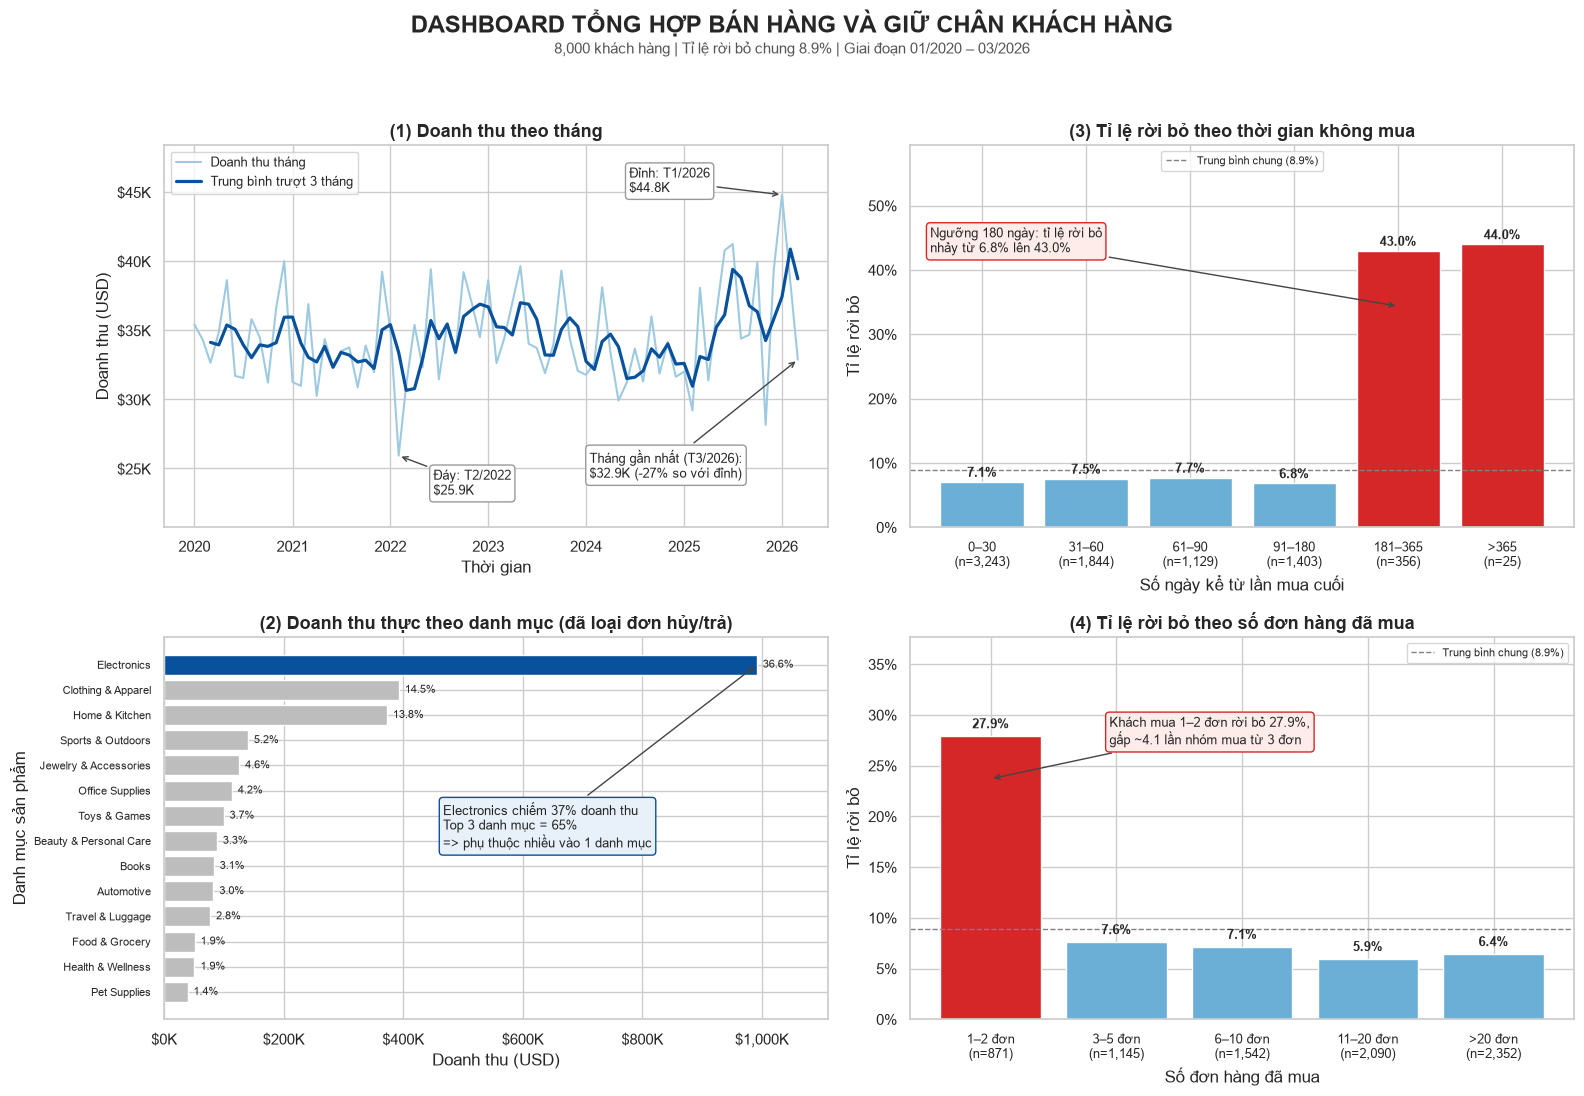

In [9]:
# Ghép 4 biểu đồ thành dashboard 2x2
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
ve_doanh_thu_thang(axes[0, 0])
ve_churn_theo_ngay(axes[0, 1])
ve_doanh_thu_danh_muc(axes[1, 0])
ve_churn_theo_don(axes[1, 1])

fig.suptitle("DASHBOARD TỔNG HỢP BÁN HÀNG VÀ GIỮ CHÂN KHÁCH HÀNG", fontsize=17, fontweight="bold", y=0.995)
fig.text(0.5, 0.955,
         f"{len(customers):,} khách hàng | Tỉ lệ rời bỏ chung {churn_all:.1%} | "
         f"Giai đoạn {monthly_t['ngay'].min():%m/%Y} – {monthly_t['ngay'].max():%m/%Y}",
         ha="center", fontsize=11, color="#555")
plt.tight_layout(rect=[0, 0, 1, 0.95])
import os; os.makedirs("../report", exist_ok=True)
plt.savefig("../report/dashboard_ban_hang.png", dpi=150, bbox_inches="tight")
plt.show()

### Điểm rút ra từ dashboard

- Doanh thu tháng khá phẳng quanh $33–36 nghìn qua các năm; đỉnh T1/2026 sau đó giảm mạnh về T3/2026, cần theo dõi xem đây là biến động mùa vụ hay xu hướng.
- Electronics chiếm ~37% doanh thu thực và top 3 danh mục chiếm ~65% → rủi ro tập trung vào một vài danh mục.
- Rời bỏ **không đều**: tăng vọt khi khách quá 180 ngày không mua (~43% so với ~7%) và cao ở khách mới chỉ mua 1–2 đơn (~28%).

## 3 đề xuất giữ chân khách hàng

### Đề xuất 1 — Chiến dịch "kéo khách quay lại trước mốc 180 ngày"

1. **Nhóm khách mục tiêu & vấn đề phát hiện:** Biểu đồ (3) cho thấy tỉ lệ rời bỏ gần như phẳng ở ~7% khi khách không mua dưới 180 ngày, rồi nhảy lên **~43%** sau mốc này. Có **692 khách** đang ở 120–180 ngày (chi tiêu tích lũy ~$1,05 triệu) và **217 khách** đã quá 180 ngày nhưng chưa rời bỏ (chi tiêu tích lũy ~$386 nghìn).
2. **Giải pháp hành động:** Tự động hóa chuỗi email/SMS theo mốc ngày 90 → 120 → 150: nhắc sản phẩm trong danh mục yêu thích, tặng mã giảm giá có hạn dùng kết thúc *trước ngày 180*. Với khách đã quá 180 ngày, gửi ưu đãi "quay lại" mạnh hơn.
3. **Tác động kỳ vọng:** Nếu kéo lại được 20% trong 217 khách đã quá 180 ngày (giả định), giữ được ~43 khách, bảo toàn ~$77 nghìn chi tiêu tích lũy và ngăn cú nhảy rời bỏ ở nhóm sắp vượt ngưỡng.

### Đề xuất 2 — Chăm sóc riêng nhóm khách chi tiêu cao (VIP)

1. **Nhóm khách mục tiêu & vấn đề phát hiện:** Top 10 có tỉ lệ rời bỏ **20%** so với **8,94%** chung (xem Câu 9). Dù mẫu nhỏ, mỗi khách trị giá trung bình ~$30 nghìn. Trong số còn lại, C04988 (139 ngày không mua), C00263 (181 ngày) đang ở vùng nguy hiểm; C05131 có 11 lượt trả hàng trên 79 đơn.
2. **Giải pháp hành động:** Gán chuyên viên chăm sóc riêng cho Top 10 (mở rộng dần ra nhóm top 1% chi tiêu); đặt cảnh báo khi khách VIP quá ~75 ngày không mua; chủ động liên hệ xử lý vấn đề trả hàng/chất lượng, ưu tiên giao hàng và hỗ trợ.
3. **Tác động kỳ vọng:** Giảm tỉ lệ rời bỏ Top 10 từ 20% xuống 10% đồng nghĩa giữ thêm khoảng 1 khách ≈ $30 nghìn chi tiêu tích lũy, với chi phí chăm sóc rất nhỏ so với giá trị.

### Đề xuất 3 — Chương trình onboarding đẩy khách mới lên đơn thứ 3

1. **Nhóm khách mục tiêu & vấn đề phát hiện:** Biểu đồ (4) cho thấy khách mới mua 1–2 đơn có tỉ lệ rời bỏ **~28%**, cao gấp ~4 lần nhóm mua từ 3 đơn trở lên (~6–8%). Nhóm này có **871 khách**; và nhóm chi tiêu thấp nhất (10% đáy) cũng rời bỏ ~22%.
2. **Giải pháp hành động:** Voucher cho đơn thứ 2 và thứ 3 trong 30 ngày, gợi ý sản phẩm bổ trợ theo `preferred_category`, nhắc các sản phẩm trong wishlist (khách có trung bình ~4,4 mục yêu thích chưa mua), đồng thời khai thác Electronics làm "sản phẩm cửa ngõ" nhưng cross-sell sang Home & Kitchen, Clothing để giảm phụ thuộc vào một danh mục.
3. **Tác động kỳ vọng:** Giảm 25% tỉ lệ rời bỏ tương đối của nhóm này (từ ~28% xuống ~21%) giữ lại khoảng 60 khách (giả định), đồng thời tăng tần suất mua và đa dạng hóa doanh thu.

> **Lưu ý:** các con số "tác động kỳ vọng" là kịch bản giả định để ước lượng quy mô, cần A/B test để xác nhận hiệu quả thực tế.